<img src="recursos/logo_UTN.svg" align="right" width="150" /> 

#### Teoría de Circuitos II

# Tarea Semanal 8

Docentes: *LLAMEDO SORIA, Mariano* y *MOHAROS, David*

Autor: *MARCHESI, Matías Sebastián*


## Introducción

En este trabajo se busca determinar los componentes que integran dos dipolos a partir de sus funciones impedancia y de ciertas condiciones dadas en la consigna. Para ello, se utilizará el método de síntesis por remoción de elementos, obteniendo progresivamente los valores de los componentes y reconstruyendo los circuitos correspondientes.

Finalmente, se verificarán los resultados mediante herramientas de Python y simulaciones en LTspice, comparando las características de las impedancias obtenidas.

## Ejercicio 1

Busco determinar los componentes del dipolo de la consigna a partir de la información sobre los ceros y polos de su función impedancia $Z(s)$.

La pulsación natural no amortiguada y el coeficiente de amortiguamiento asociados a los ceros son:

$$\omega_0 = 1\ \frac{\text{rad}}{\text{s}}, \qquad \zeta = 0,5$$

Además, se conocen los polos de la impedancia:

$$p_1=-1$$

$$p_{2,3}=\sqrt{5}\,e^{\pm j116,6^\circ}$$

Planteo la función impedancia como un cociente de polinomios a partir de sus ceros y polos.

Para los ceros, el polinomio asociado es:

$$s^2+2\zeta\omega_0s+\omega_0^2=s^2+s+1$$

Los polos complejos conjugados tienen módulo $\sqrt{5}$ y ángulo $\pm116,6^\circ$. Aproximando sus valores a $-1\pm j2$, el polinomio asociado queda:

$$
(s+1-j2)(s+1+j2)=(s+1)^2+4=s^2+2s+5
$$

Considerando también el polo real $p_1=-1$, obtengo el polinomio del denominador:

$$
D(s)=(s+1)(s^2+2s+5)
$$

Finalmente la función impedancia resulta:

$$
\boxed{Z(s)=\frac{s^2+s+1}{(s+1)(s^2+2s+5)}}
$$

Para realizar la síntesis, voy a remover sucesivamente los componentes de $Z(s)$, comenzando por los elementos asociados a los polos y ceros conocidos.

Primero, tomo el circuito de la consigna como referencia para identificar los componentes que voy obteniendo durante el procedimiento.

<div style="text-align: center;">
  <img src="recursos/ejercicio1_sinvalores.png" width="600">
</div>

### Primera remoción: $C_1$

Viendo el circuito, puedo remover directamente $C_1$. Como se encuentra en derivación, paso a trabajar con la admitancia $Y(s)$ para realizar la primera remoción.

$$Y(s)=\frac{1}{Z(s)}=\frac{(s+1)(s^2+2s+5)}{s^2+s+1}$$

Como tengo un capacitor en derivación, calculo $k_{\infty}$ mediante el límite cuando $s$ tiende a infinito:

$$
k_{\infty}=\lim_{s\to\infty}\frac{Y(s)}{s}
=\lim_{s\to\infty}\frac{(s+1)(s^2+2s+5)}{s(s^2+s+1)}
=1
$$

Por lo tanto, el valor del capacitor es:

$$C_1=k_{\infty}=1\ \text{F}$$

Ahora calculo la admitancia restante, $Y_2(s)$, restando la contribución del capacitor a $Y(s)$:

$$
Y_2(s)=Y(s)-sC_1
$$

Reemplazando el valor obtenido:

$$
Y_2(s)=\frac{(s+1)(s^2+2s+5)}{s^2+s+1}-s
$$

Operando:

$$
Y_2(s)=\frac{s^3+3s^2+7s+5-s(s^2+s+1)}{s^2+s+1}
$$

Finalmente:

$$
\boxed{Y_2(s)=\frac{2s^2+6s+5}{s^2+s+1}}
$$

### Segunda remoción: $R_1$

Ahora quiero remover $R_1$ en derivación. Para ello, resto de la admitancia $Y_2(s)$ la contribución de la resistencia:

$$
Y_4(s)=Y_2(s)-Y_{R_1}(s)
$$

Como se trata de una resistencia en derivación, su contribución a la admitancia es:

$$
Y_{R_1}(s)=\frac{1}{R_1}
$$

Por lo tanto:

$$
Y_4(s)=Y_2(s)-\frac{1}{R_1}
$$

Calculo el valor de $\frac{1}{R_1}$ mediante el límite cuando $s$ tiende a infinito:

$$
\frac{1}{R_1}=\lim_{s\to\infty}Y_2(s)
=\lim_{s\to\infty}\frac{2s^2+6s+5}{s^2+s+1}=2
$$

Entonces, obtengo el valor de la resistencia:

$$
\boxed{R_1=\frac{1}{2}\ \Omega}
$$

Ahora calculo la admitancia restante, $Y_4(s)$, reemplazando el valor obtenido:

$$
Y_4(s)=\frac{2s^2+6s+5}{s^2+s+1}-2
$$

Operando:

$$
Y_4(s)=\frac{2s^2+6s+5-2(s^2+s+1)}{s^2+s+1}
$$

Finalmente:

$$
\boxed{Y_4(s)=\frac{4s+3}{s^2+s+1}}
$$

### Tercera remoción: $L_1$

Ahora quiero remover $L_1$, que está conectado en serie. Por este motivo, conviene pasar de la admitancia $Y_4(s)$ a la impedancia, ya que las contribuciones de los elementos en serie se restan directamente de la impedancia total.

Planteo entonces:

$$
Z_4(s)=\frac{s^2+s+1}{4s+3}
$$

Como tengo un inductor en serie, calculo su valor mediante el límite cuando $s$ tiende a infinito:

$$
L_1=\lim_{s\to\infty}\frac{Z_4(s)}{s}
=\lim_{s\to\infty}\frac{s^2+s+1}{s(4s+3)}
=\frac{1}{4}
$$

Por lo tanto, el valor del inductor es:

$$
\boxed{L_1=\frac{1}{4}\ \text{H}}
$$

Ahora calculo la impedancia restante, $Z_6(s)$, restando la contribución del inductor:

$$
Z_6(s)=Z_4(s)-sL_1
$$

Reemplazando el valor obtenido:

$$
Z_6(s)=\frac{s^2+s+1}{4s+3}-\frac{s}{4}
$$

Operando:

$$
Z_6(s)=\frac{4(s^2+s+1)-s(4s+3)}{4(4s+3)}
$$

Finalmente, obtengo:

$$
\boxed{Z_6(s)=\frac{s+4}{16s+12}}
$$

Para comprobar si la función obtenida es real positiva (FRP), utilizo la función `isFRP` del módulo `pytc2.remociones`. Esta herramienta permite verificar si la inmitancia simbólica cumple las condiciones de una función real positiva, lo que me permite comprobar si puedo continuar con el proceso de síntesis por remoción de elementos.

In [21]:
import sympy as sp
from pytc2.general import s
from pytc2.remociones import isFRP

Z6 = (s + 4) / (16*s + 12)

print("Z6(s) =", Z6, "es FRP?")
if isFRP(Z6):
    print("SI")
else:
    print("NO")

Z6(s) = (s + 4)/(16*s + 12) es FRP?
SI


### Cuarta remoción: $R_2$

Ahora quiero remover $R_2$, que está conectado en serie. Por lo tanto, trabajo directamente sobre la impedancia $Z_6(s)$ y resto la contribución de la resistencia para obtener $Z_8(s)$.

Como se trata de una resistencia en serie, calculo su valor mediante el límite cuando $s$ tiende a infinito:

$$
R_2=\lim_{s\to\infty}Z_6(s)
=\lim_{s\to\infty}\frac{s+4}{16s+12}
=\frac{1}{16}
$$

Por lo tanto, obtengo:

$$
\boxed{R_2=\frac{1}{16}\ \Omega}
$$

Ahora calculo la impedancia restante, $Z_8(s)$, restando la contribución de la resistencia:

$$
Z_8(s)=Z_6(s)-R_2
$$

Reemplazando los valores:

$$
Z_8(s)=\frac{s+4}{16s+12}-\frac{1}{16}
$$

Operando:

$$
Z_8(s)=\frac{16(s+4)-(16s+12)}{16(16s+12)}
$$

Finalmente, obtengo:

$$
\boxed{Z_8(s)=\frac{13}{64s+48}}
$$

### Quinta remoción: $C_2$

Como $C_2$ está conectado en derivación, conviene pasar de la impedancia $Z_8(s)$ a la admitancia para poder restar directamente la contribución del capacitor.

Planteo entonces:

$$
Y_8(s)=\frac{64s+48}{13}
$$

Como tengo un capacitor en derivación, calculo su valor mediante el límite cuando $s$ tiende a infinito:

$$
C_2=\lim_{s\to\infty}\frac{Y_8(s)}{s}
=\lim_{s\to\infty}\frac{64s+48}{13s}
=\frac{64}{13}
$$

Por lo tanto, obtengo:

$$
\boxed{C_2=\frac{64}{13}\ \text{F}}
$$

Ahora calculo la admitancia restante, $Y_{10}(s)$, restando la contribución del capacitor:

$$
Y_{10}(s)=Y_8(s)-sC_2
$$

Reemplazando:

$$
Y_{10}(s)=\frac{64s+48}{13}-s\frac{64}{13}
$$

Finalmente:

$$
\boxed{Y_{10}(s)=\frac{48}{13}\ \text{S}}
$$

Observo que $Y_{10}(s)$ es una admitancia constante, por lo que corresponde directamente a la conductancia de la resistencia $R_3$:

$$
Y_{10}(s)=\frac{1}{R_3}
$$

Despejando:

$$
R_3=\frac{1}{Y_{10}(s)}=\frac{13}{48}\ \Omega
$$

Por lo tanto, obtengo el último componente:

$$
\boxed{R_3=\frac{13}{48}\ \Omega}
$$

Con esta última remoción, ya determiné todos los componentes del dipolo.

### Resultados finales

Luego de completar las cinco remociones, obtuve los valores de todos los componentes que conforman el dipolo.

| Componente | Valor obtenido |
|---|---:|
| $C_1$ | $1\ \text{F}$ |
| $R_1$ | $\frac{1}{2}\ \Omega$ |
| $L_1$ | $\frac{1}{4}\ \text{H}$ |
| $R_2$ | $\frac{1}{16}\ \Omega$ |
| $C_2$ | $\frac{64}{13}\ \text{F}$ |
| $R_3$ | $\frac{13}{48}\ \Omega$ |

Con estos valores, queda determinada la composición del dipolo original. A continuación, puedo reconstruir su impedancia de entrada a partir de los componentes obtenidos y verificar que coincida con la función impedancia planteada inicialmente.

### Verificación de la impedancia de entrada

A partir de los valores obtenidos, reconstruyo la impedancia de entrada del circuito. Para ello, considero las conexiones de los componentes: $C_1$ y $R_1$ están en derivación a la entrada, mientras que $R_2$ y $L_1$ están en serie con el paralelo formado por $C_2$ y $R_3$.

La impedancia equivalente del paralelo de salida es:

$$
Z_p(s)=\left(\frac{1}{sC_2} \parallel R_3\right)
=\frac{R_3}{1+sC_2R_3}
$$

Luego, la rama formada por $R_2$, $L_1$ y $Z_p(s)$ tiene una impedancia:

$$
Z_{\text{rama}}(s)=R_2+sL_1+Z_p(s)
$$

Finalmente, calculo la impedancia de entrada considerando las ramas en paralelo:

$$
Z_{in}(s)=
\left(
sC_1+\frac{1}{R_1}+\frac{1}{Z_{\text{rama}}(s)}
\right)^{-1}
$$

Reemplazando los valores de los componentes obtenidos, verifico si la impedancia reconstruida coincide con la función original $Z(s)$.

In [22]:
import sympy as sp
from pytc2.general import s

C1 = 1
R1 = 1/2
L1 = 1/4
R2 = 1/16
C2 = 64/13
R3 = 13/48

#  C2 || R3
Zp = sp.factor(1 / (s*C2 + 1/R3))

# R2 + L1 + (C2 || R3)
Zrama = sp.factor(R2 + s*L1 + Zp)

Zin = sp.factor(1 / (s*C1 + 1/R1 + 1/Zrama))

# Función impedancia original
Z = (s**2 + s + 1) / ((s + 1)*(s**2 + 2*s + 5))

diferencia = sp.factor(Zin - Z)

print("¿Coinciden las funciones?")
if diferencia == 0:
    print("SI")
else:
    print("NO")


¿Coinciden las funciones?
SI


### Diagrama de Bode

Para realizar una última verificación, grafico los diagramas de Bode de la impedancia original $Z(s)$ y de la impedancia reconstruida $Z_{in}(s)$. Comparo tanto la magnitud como la fase en función de la frecuencia.

Si la síntesis es correcta, ambas curvas deben superponerse. Luego, puedo contrastar estos resultados con los obtenidos mediante la simulación en LTspice.

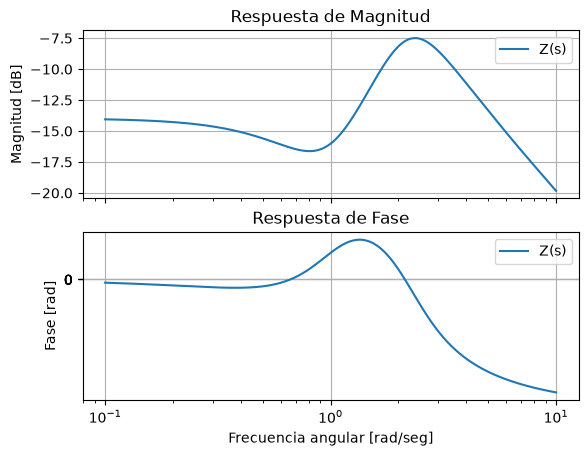

In [18]:
from pytc2.general import s, symbfunc2tf
from pytc2.sistemas_lineales import bodePlot

Z_tf = symbfunc2tf(Z)

bodePlot(
    Z_tf,
    filter_description='Z(s)',
    xaxis='omega'
);

### Comprobación con LTSpice

Para verificar los resultados obtenidos, realicé una simulación del circuito reconstruido en LTspice mediante un barrido `.ac dec 10000 1u 1Meg`.

Comparo estas gráficas con los diagramas de Bode obtenidos en Python para comprobar que el circuito sintetizado presenta el comportamiento esperado.

#### Módulo 

<div style="text-align: center;">
  <img src="recursos/ejercicio1_modulo.png" width="800">
</div>

#### Fase

<div style="text-align: center;">
  <img src="recursos/ejercicio1_fase.png" width="800">
</div>

Comprobando que lo obtenido en Python es lo mismo que en LTSpice.

## Ejercicio 2

Busco determinar los valores de los componentes que integran el dipolo de la consigna a partir de su función impedancia $Z(s)$ y de las constantes de tiempo conocidas.

La función impedancia está dada por:

$$
Z(s)=\frac{s^2+6s+8}{s^2+4s+3}
$$

Además, se conocen las siguientes constantes de tiempo:

$$
C_1R_1=\frac{1}{5}
$$

$$
C_2R_2=\frac{1}{4}
$$

Para determinar los componentes del circuito, voy a realizar remociones sucesivas sobre la función impedancia, teniendo en cuenta la conexión serie o en derivación de cada elemento. Como los valores de $Z_1$, $Z_2$ y $Z_3$ son desconocidos, los iré determinando a partir del procedimiento de síntesis.

<div style="text-align: center;">
  <img src="recursos/ejercicio2_sinvalores.png" width="600">
</div>

### Determinación de $Z_1$

Partimos de la función impedancia dada en la consigna:

$$
Z(s)=\frac{s^2+6s+8}{s^2+4s+3}
$$

Para determinar $Z_1$, utilizo la constante de tiempo conocida:

$$
R_1C_1=\frac{1}{5}
$$

La impedancia de la rama formada por $R_1$ y $C_1$, conectados en serie, es:

$$
Z_{R_1C_1}(s)=R_1+\frac{1}{sC_1}
$$

Evaluando en $s=-5$, obtengo:

$$
Z_{R_1C_1}(-5)=R_1-\frac{1}{5C_1}=0
$$

Esto se debe a que $R_1C_1=\frac{1}{5}$. Por lo tanto, la rama presenta una impedancia nula y equivale a un cortocircuito. En consecuencia, la impedancia de entrada queda determinada únicamente por $Z_1$:

$$
Z(-5)=Z_1
$$

Evaluando la función impedancia:

$$
Z_1=\frac{(-5)^2+6(-5)+8}{(-5)^2+4(-5)+3}
$$

$$
Z_1=\frac{25-30+8}{25-20+3}
$$

Finalmente, obtengo:

$$
\boxed{Z_1=\frac{3}{8}\ \Omega}
$$

### Primera remoción: $Z_1$

Ahora que conozco $Z_1$, puedo remover su contribución de la impedancia original para obtener la función residual $Z_{\mathrm{rem1}}(s)$.

Como $Z_1$ está conectado en serie, resto directamente su impedancia:

$$
Z_{\mathrm{rem1}}(s)=Z(s)-Z_1
$$

Reemplazando:

$$
Z_{\mathrm{rem1}}(s)=
\frac{s^2+6s+8}{s^2+4s+3}-\frac{3}{8}
$$

Operando:

$$
Z_{\mathrm{rem1}}(s)=
\frac{8(s^2+6s+8)-3(s^2+4s+3)}
{8(s^2+4s+3)}
$$

$$
Z_{\mathrm{rem1}}(s)=
\frac{5s^2+36s+55}{8(s^2+4s+3)}
$$

Factorizando el numerador y el denominador:

$$
Z_{\mathrm{rem1}}(s)=
\frac{5(s+5)(s+\frac{11}{5})}
{8(s+1)(s+3)}
$$

Por lo tanto, la impedancia residual luego de remover $Z_1$ es:

$$
\boxed{
Z_{\mathrm{rem1}}(s)=
\frac{5(s+5)(s+\frac{11}{5})}
{8(s+1)(s+3)}
}
$$

### Segunda remoción: Tanque $R_1$ $C_1$

Partiendo de la impedancia residual obtenida en la remoción anterior:

$$
Z_{\mathrm{rem1}}(s)=
\frac{5(s+5)(s+\frac{11}{5})}
{8(s+1)(s+3)}
$$

Como la rama formada por $R_1$ y $C_1$ está conectada en derivación, paso a trabajar con la admitancia correspondiente:

$$
Y_{\mathrm{rem1}}(s)=\frac{1}{Z_{\mathrm{rem1}}(s)}
$$

Por lo tanto:

$$
Y_{\mathrm{rem1}}(s)=
\frac{8(s+1)(s+3)}
{5(s+5)(s+\frac{11}{5})}
$$

La admitancia de la rama $R_1C_1$, cuyos componentes están conectados en serie, es:

$$
Y_{R_1C_1}(s)=
\frac{1}{R_1+\frac{1}{sC_1}}
$$

Operando:

$$
Y_{R_1C_1}(s)=
\frac{s\frac{1}{R_1}}{s+\frac{1}{R_1C_1}}
$$

Como conozco que $R_1C_1=\frac{1}{5}$, puedo escribir:

$$
Y_{R_1C_1}(s)=
\frac{s\frac{1}{R_1}}{s+5}
$$

Para determinar $R_1$, utilizo el residuo de la admitancia en el polo $s=-5$. Este polo corresponde a la constante de tiempo de la rama que quiero remover.

Calculo primero el residuo de la admitancia residual:

$$\frac{1}{R_1} = \lim_{s\to-5}\frac{(s+5)}{s}Y_{\mathrm{rem1}}(s)=
\lim_{s\to-5}
\frac{(s+5)}{s}\frac{8(s+1)(s+3)}
{5(s+\frac{11}{5})(s+5)} = \frac{32}{35}
$$

Entonces:
$$R_1 = \frac{35}{32} \Omega$$

Conocido el valor de la resistencia, calculo $C_1$ utilizando la constante de tiempo dada en la consigna:

$$
R_1C_1=\frac{1}{5}
$$

$$
C_1=\frac{1}{5R_1}
=\frac{1}{5\cdot\frac{35}{32}}
$$

Finalmente:

$$
\boxed{C_1=\frac{32}{175}\ F}
$$


Ahora que conozco los dos componentes de la rama, puedo remover su contribución de la admitancia residual:

$$
Y_{\mathrm{rem2}}(s)=
Y_{\mathrm{rem1}}(s)-Y_{R_1C_1}(s)
$$

Reemplazando las expresiones obtenidas:

$$Y_{\mathrm{rem2}}(s)=
\frac{8(s+1)(s+3)}
{5(s+5)(s+\frac{11}{5})}
-\frac{s\frac{32}{35}}{s+5}
$$

Operando y simplificando:

$$
\boxed{
Y_{\mathrm{rem2}}(s)=
\frac{24}{35}\frac{s+\frac{7}{5}}
{s+\frac{11}{5}}
}
$$


Para continuar con la siguiente remoción, vuelvo a expresar la función residual como impedancia:

$$
Z_{\mathrm{rem2}}(s)=
\frac{1}{Y_{\mathrm{rem2}}(s)}
$$

Por lo tanto, obtengo:

$$
\boxed{
Z_{\mathrm{rem2}}(s)= \frac{35}{24}
\frac{s+\frac{11}{5}}
{s+\frac{7}{5}}
}
$$

Esta es la impedancia residual luego de remover la rama formada por $R_1$ y $C_1$. A partir de ella, puedo continuar con la determinación de los elementos restantes del dipolo.

### Determinación de $Z_2$

La rama formada por $R_2$ y $C_2$ introduce un cero en $s=-4$, debido a que su constante de tiempo es:

$$
R_2C_2=\frac{1}{4}
$$

Por lo tanto, evaluando la impedancia residual en dicho punto, obtengo directamente el valor de $Z_2$:

$$
Z_2=Z_{\mathrm{rem2}}(-4)
$$

Reemplazando:

$$
Z_2=\frac{35}{24}
\frac{-4+\frac{11}{5}}{-4+\frac{7}{5}}
$$

$$
Z_2=\frac{35}{24}
\frac{-\frac{9}{5}}{-\frac{13}{5}}
$$

Finalmente:

$$
\boxed{Z_2=\frac{105}{104}\ \Omega}
$$

### Tercera remoción: $Z_2$

Una vez conocido el valor de $Z_2$, puedo remover su contribución de la impedancia residual obtenida anteriormente:

$$
Z_{\mathrm{rem3}}(s)=Z_{\mathrm{rem2}}(s)-Z_2
$$

Reemplazando las expresiones correspondientes:

$$
Z_{\mathrm{rem3}}(s)=
\frac{35}{24}\frac{s+\frac{11}{5}}{s+\frac{7}{5}}
-\frac{105}{104}
$$

Operando:

$$
Z_{\mathrm{rem3}}(s)=
\frac{\frac{35}{24}\left(s+\frac{11}{5}\right)
-\frac{105}{104}\left(s+\frac{7}{5}\right)}
{s+\frac{7}{5}}
$$

Simplificando y factorizando el numerador, obtengo:

$$
\boxed{
Z_{\mathrm{rem3}}(s)=
\frac{35}{78}\frac{s+4}{s+\frac{7}{5}}
}
$$

Esta es la impedancia residual luego de remover $Z_2$. A partir de ella, puedo continuar con la siguiente remoción.

### Tercera remoción: Tanque $R_2$ $C_2$

Partiendo de la impedancia residual obtenida luego de remover $Z_2$:

$$
Z_{\mathrm{rem3}}(s)=
\frac{35}{78}\frac{s+4}{s+\frac{7}{5}}
$$

La admitancia residual correspondiente es:

$$
Y_{\mathrm{rem3}}(s)=\frac{1}{Z_{\mathrm{rem3}}(s)}
$$

Por lo tanto:

$$
Y_{\mathrm{rem3}}(s)=
\frac{78}{35}\frac{s+\frac{7}{5}}{s+4}
$$

La admitancia de la rama serie $R_2C_2$ es:

$$
Y_{R_2C_2}(s)=
\frac{s\frac{1}{R_2}}{s+\frac{1}{R_2C_2}}
$$

Como conozco que $R_2C_2=\frac{1}{4}$, puedo escribir:

$$
Y_{R_2C_2}(s)=
\frac{s\frac{1}{R_2}}{s+4}
$$

Para determinar $R_2$, utilizo el residuo de la admitancia en el polo $s=-4$:

$$
\frac{1}{R_2}=
\lim_{s\to-4}\frac{s+4}{s}Y_{\mathrm{rem3}}(s)
$$

Reemplazando:

$$
\frac{1}{R_2}=
\lim_{s\to-4}
\frac{s+4}{s}
\frac{78}{35}\frac{s+\frac{7}{5}}{s+4}
$$

Evaluando:

$$
\frac{1}{R_2}=
-\frac{78}{35}\frac{-\frac{13}{5}}{4}
=\frac{507}{350}
$$

Por lo tanto:

$$
\boxed{R_2=\frac{350}{507}\ \Omega}
$$

Conocido el valor de la resistencia, calculo $C_2$ utilizando la constante de tiempo dada en la consigna:

$$
R_2C_2=\frac{1}{4}
$$

$$
C_2=\frac{1}{4R_2}
=\frac{1}{4\cdot\frac{350}{507}}
$$

Finalmente:

$$
\boxed{C_2=\frac{507}{1400}\ \mathrm{F}}
$$

Ahora que conozco los componentes del tanque $R_2C_2$, puedo remover su contribución de la admitancia residual:

$$
Y_{\mathrm{rem4}}(s)=
Y_{\mathrm{rem3}}(s)-Y_{R_2C_2}(s)
$$

Reemplazando las expresiones obtenidas:

$$Y_{\mathrm{rem4}}(s)=\frac{78}{35}\frac{s+\frac{7}{5}}{s+4}-
\frac{\frac{507}{350}s}{s+4}
$$

Operando y simplificando:

$$
Y_{\mathrm{rem4}}(s)=
\frac{\frac{78}{35}\left(s+\frac{7}{5}\right)-\frac{507}{350}s}{s+4}
$$

$$
Y_{\mathrm{rem4}}(s)=
\frac{\frac{273}{350}s+\frac{1092}{350}}{s+4}
$$

Por lo tanto, la admitancia residual luego de remover el tanque $R_2C_2$ es:

$$
\boxed{
Y_{\mathrm{rem4}}(s)=
\frac{39}{50}\frac{s+4}{s+4}
}
$$

Simplificando:

$$
\boxed{Y_{\mathrm{rem4}}(s)=\frac{39}{50}}
$$

Como $Y_{\mathrm{rem4}}(s)$ es constante, la función residual ya no depende de la variable compleja $s$. Esto significa que no quedan elementos reactivos por determinar y que la admitancia restante corresponde a una resistencia pura.

Por lo tanto, la resistencia equivalente asociada a esta admitancia es:

$$
R_3=\frac{1}{Y_{\mathrm{rem4}}}
$$

$$
\boxed{R_3=\frac{50}{39}\ \Omega}
$$

De esta manera, queda determinado el último elemento del dipolo y se completa el proceso de síntesis del circuito.

### Resultados finales

Luego de completar las remociones, obtuve los valores de todos los componentes que conforman el dipolo.

| Componente | Valor obtenido |
|---|---:|
| $Z_1$ | $\frac{3}{8}\ \Omega$ |
| $R_1$ | $\frac{35}{32}\ \Omega$ |
| $C_1$ | $\frac{32}{175}\ \text{F}$ |
| $Z_2$ | $\frac{105}{104}\ \Omega$ |
| $R_2$ | $\frac{350}{507}\ \Omega$ |
| $C_2$ | $\frac{507}{1400}\ \text{F}$ |
| $R_3$ | $\frac{50}{39}\ \Omega$ |

Con estos valores, queda determinada la composición del dipolo original. A continuación, puedo reconstruir su impedancia de entrada a partir de los componentes obtenidos y verificar que coincida con la función impedancia planteada inicialmente.

### Verificación de la impedancia de entrada

A partir de los valores obtenidos, reconstruyo la impedancia de entrada del circuito. Para ello, considero las conexiones de los componentes: $Z_1$ está en serie con el paralelo formado por la rama $R_1C_1$ y el resto del circuito. A continuación, $Z_2$ está en serie con el paralelo formado por la rama $R_2C_2$ y la impedancia terminal $Z_3$.

La impedancia de la primera rama, formada por $R_1$ y $C_1$ en serie, es:

$$
Z_{R_1C_1}(s)=R_1+\frac{1}{sC_1}
$$

La impedancia de la segunda rama, formada por $R_2$ y $C_2$ en serie, es:

$$
Z_{R_2C_2}(s)=R_2+\frac{1}{sC_2}
$$

Luego, calculo la impedancia equivalente del paralelo de salida:

$$
Z_p(s)=Z_{R_2C_2}(s)\parallel Z_3
$$

La rama que contiene $Z_2$ queda entonces:

$$
Z_{\mathrm{rama2}}(s)=Z_2+Z_p(s)
$$

Finalmente, la impedancia de entrada es:

$$
Z_{\mathrm{in}}(s)=Z_1+
\left(
Z_{R_1C_1}(s)\parallel Z_{\mathrm{rama2}}(s)
\right)
$$

Reemplazando los valores de los componentes obtenidos, verifico si la impedancia reconstruida coincide con la función original $Z(s)$.

In [6]:
import sympy as sp
from pytc2.general import s

Z1 = sp.Rational(3, 8)
R1 = sp.Rational(35, 32)
C1 = sp.Rational(32, 175)

Z2 = sp.Rational(105, 104)
R2 = sp.Rational(350, 507)
C2 = sp.Rational(507, 1400)

Z3 = sp.Rational(50, 39)

# R1-C1 en serie
ZR1C1 = sp.factor(R1 + 1 / (s*C1))

# R2-C2 en serie
ZR2C2 = sp.factor(R2 + 1 / (s*C2))

# (R2 + C2) || Z3
Zp = sp.factor(1 / (1/ZR2C2 + 1/Z3))

# Z2 + paralelo de salida
Zrama2 = sp.factor(Z2 + Zp)

# Impedancia de entrada
Zin = sp.factor(Z1 + 1 / (1/ZR1C1 + 1/Zrama2))

# Función impedancia original
Z = (s**2 + 6*s + 8) / (s**2 + 4*s + 3)

diferencia = sp.factor(Zin - Z)

print("\n¿Coinciden las funciones?")
if diferencia == 0:
    print("SI")
else:
    print("NO")


¿Coinciden las funciones?
SI


### Diagrama de Bode

Para realizar una última verificación, grafico los diagramas de Bode de la impedancia original $Z(s)$ y de la impedancia reconstruida $Z_{\mathrm{in}}(s)$. Comparo tanto la magnitud como la fase en función de la frecuencia.

Si la síntesis es correcta, ambas curvas deben superponerse. Luego, puedo contrastar estos resultados con los obtenidos mediante la simulación en LTspice.

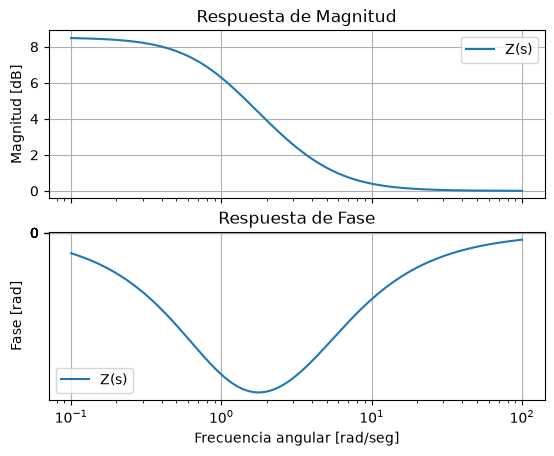

In [8]:

from pytc2.general import s, symbfunc2tf
from pytc2.sistemas_lineales import bodePlot

Z_tf = symbfunc2tf(Z)

bodePlot(
    Z_tf,
    filter_description='Z(s)',
    xaxis='omega'
);


### Comprobación con LTspice

Para verificar los resultados obtenidos, realicé una simulación del circuito reconstruido en LTspice mediante un barrido `.ac dec 10000 1u 1Meg`.

Comparo estas gráficas con el diagrama de Bode obtenido en Python para comprobar que el circuito sintetizado presenta el comportamiento esperado.

#### Módulo

<div style="text-align: center;">
  <img src="recursos/ejercicio2_modulo.png" width="800">
</div>

#### Fase

<div style="text-align: center;">
  <img src="recursos/ejercicio2_fase.png" width="800">
</div>

Las gráficas permiten comprobar que el comportamiento obtenido mediante la simulación en LTspice coincide con el esperado a partir de la función impedancia original.

#### Impedancia en continua

Para comprobar el valor de la impedancia en continua, ubico el cursor en una frecuencia suficientemente baja y verifico que la magnitud se aproxime al valor teórico de $Z(0)$.

<div style="text-align: center;">
  <img src="recursos/ejercicio2_DC.png" width="800">
</div>

El cursor indica una magnitud de aproximadamente $2{,}6667\ \Omega$, coincidente con el valor calculado:

$$
Z(0)=\frac{8}{3}\ \Omega
$$

#### Impedancia a altas frecuencias

De manera análoga, ubico el cursor en una frecuencia suficientemente elevada para comprobar el comportamiento asintótico de la impedancia.

<div style="text-align: center;">
  <img src="recursos/ejercicio2_inf.png" width="800">
</div>

El cursor indica una magnitud de $1\ \Omega$, coincidente con el límite teórico:

$$
Z(\infty)=1\ \Omega
$$

Ambas comprobaciones confirman que los valores extremos de la impedancia simulada coinciden con los obtenidos analíticamente.